# CIS 360 - Spring 2026 - Assignment 1

Three practical applications of Object Detection and Object Tracking technology are:

1. Self-driving vehicles
2. Cashierless checkout
3. Healthcare imaging

In [ ]:
# Import necessary libraries
import matplotlib.pyplot as plt
import cv2
import time

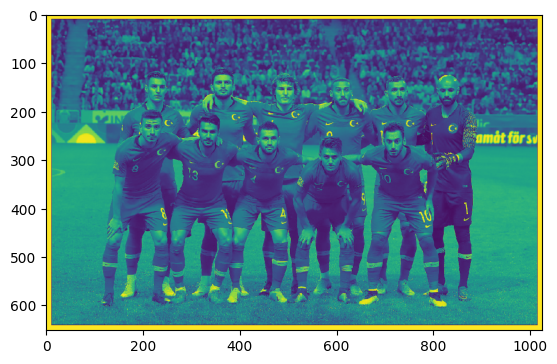

In [ ]:
# Use OpenCV to load image and convert it to grayscale
pic = cv2.imread('media/sportsteam.png')
pic = cv2.cvtColor(pic,cv2.COLOR_BGR2GRAY)
plt.imshow(pic)

In [ ]:
# Load prebuilt classifier and use it to detect faces in the image
face_classifier = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')
faces = face_classifier.detectMultiScale(pic, 1.2, 4)
print("Number of faces detected: ", len(faces))
i = 0
for (x,y,w,h) in faces:
    face = pic[y:y+h, x:x+w]
    cv2.imwrite(f'faces/{i}.jpg', face) # Save images of faces to "faces" folder
    i = i + 1

Number of faces detected:  11


There are 11 players in the picture. The classifier correctly identified all of their faces and saved images of the faces to the folder. No faces from the crowd are identified, due to their extremely small size.

In [ ]:
# Use classifier to detect faces in the video
video = cv2.VideoCapture('media/pedestrian_video.avi')
i = 0
while video.isOpened():
    time.sleep(.05)
    ret, frame = video.read()
    if not ret or frame is None:
        break
    frame = cv2.resize(frame, None,fx=2.0, fy=2.0, interpolation = cv2.INTER_LINEAR)
    grayframe = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
   
    faces = face_classifier.detectMultiScale(grayframe, 1.25, 4)
    
    for (x,y,w,h) in faces:
        face = frame[y:y+h, x:x+w]
        cv2.imwrite(f'video_faces/{i}.jpg', face) # Save images of faces to "video_faces" folder
        i = i + 1

    if cv2.waitKey(1) & 0xFF == ord('q'): 
        break

video.release()
cv2.destroyAllWindows()

I was not able to get the classifier to detect all of the faces in the video. Though the classifier did detect some faces, it also detected non-faces. The code in the cell above gave the best results.